# Regression for House Prices (Ames, Iowa)
**Team:** Amina Salamatolla, Dianna Mirtayeva

Goal: predict `SalePrice` for the 260 houses in `test.csv`. Kaggle scores submissions with RMSE in dollars, so every model here is compared on cross-validated RMSE in dollars.

Plan:
1. Look at the target and the strongest predictors
2. Clean missing values and add a few features
3. Compare several scikit-learn models with 5-fold CV
4. Blend the best models and make the submission

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, VotingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.model_selection import GridSearchCV, KFold, cross_val_predict, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
usd_k = mticker.FuncFormatter(lambda v, _: f'${v / 1000:,.0f}k')

In [2]:
# On Kaggle the files are under /kaggle/input (we want the ames/ folder, not archive/); locally they are in data/
KAGGLE_INPUT = Path('/kaggle/input')
if KAGGLE_INPUT.exists():
    found = sorted(KAGGLE_INPUT.rglob('train.csv'), key=lambda p: p.parent.name != 'ames')
    DATA_DIR = found[0].parent
else:
    DATA_DIR = Path('data')

train_df = pd.read_csv(DATA_DIR / 'train.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')

print('train:', train_df.shape, ' test:', test_df.shape)
train_df.head()

train: (1200, 81)  test: (260, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Exploring the data
The training set has 1,200 houses with 79 features plus `Id` and `SalePrice`. The test set has 260 houses without `SalePrice`.

In [3]:
train_df['SalePrice'].describe()

count      1200.000000
mean     181414.628333
std       81070.908544
min       34900.000000
25%      129900.000000
50%      163700.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

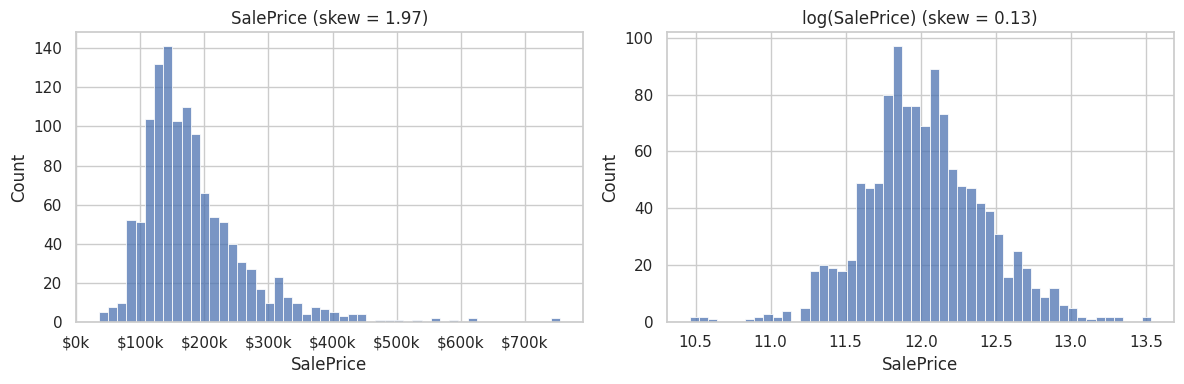

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_df['SalePrice'], bins=50, ax=axes[0])
axes[0].xaxis.set_major_formatter(usd_k)
axes[0].set_title(f"SalePrice (skew = {train_df['SalePrice'].skew():.2f})")
sns.histplot(np.log1p(train_df['SalePrice']), bins=50, ax=axes[1])
axes[1].set_title(f"log(SalePrice) (skew = {np.log1p(train_df['SalePrice']).skew():.2f})")
plt.tight_layout()
plt.show()

`SalePrice` is right-skewed (skew 1.97): a small number of expensive houses stretch the tail. After a log transform it is close to symmetric (skew 0.13), so most of our models are trained on log(SalePrice), and the predictions are converted back to dollars. Since Kaggle measures error in dollars, all CV scores below are still computed in dollars.

OverallQual     0.789
GrLivArea       0.740
TotalBsmtSF     0.642
GarageCars      0.641
GarageArea      0.623
1stFlrSF        0.619
FullBath        0.572
TotRmsAbvGrd    0.559
YearBuilt       0.523
YearRemodAdd    0.510
Name: SalePrice, dtype: float64


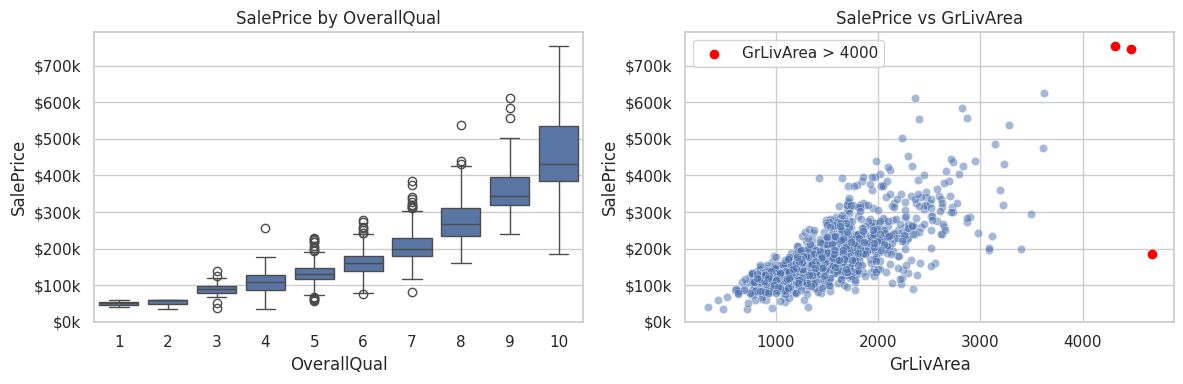

In [5]:
corr = train_df.drop(columns='Id').corr(numeric_only=True)['SalePrice'].drop('SalePrice')
top_corr = corr.sort_values(ascending=False).head(10)
print(top_corr.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=train_df, x='OverallQual', y='SalePrice', ax=axes[0])
axes[0].set_title('SalePrice by OverallQual')
axes[0].yaxis.set_major_formatter(usd_k)
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', alpha=0.5, ax=axes[1])
big = train_df[train_df['GrLivArea'] > 4000]
axes[1].scatter(big['GrLivArea'], big['SalePrice'], color='red', label='GrLivArea > 4000')
axes[1].legend()
axes[1].yaxis.set_major_formatter(usd_k)
axes[1].set_title('SalePrice vs GrLivArea')
plt.tight_layout()
plt.show()

`OverallQual` (r = 0.79) and `GrLivArea` (r = 0.74) are the strongest single predictors, and price rises steadily with quality. Three training houses have more than 4,000 sq ft of living area. Two sold for about \$750k, which fits the trend. Id 524 sold for \$184,750, far below what its size suggests. It was a partial sale (the house wasn't finished when assessed) in Edwards.

In [6]:
print(train_df.loc[train_df['GrLivArea'] > 4000, ['Id', 'GrLivArea', 'Neighborhood', 'SaleCondition', 'SalePrice']])
print(test_df.loc[test_df['GrLivArea'] > 4000, ['Id', 'GrLivArea', 'Neighborhood', 'SaleCondition']])

        Id  GrLivArea Neighborhood SaleCondition  SalePrice
523    524       4676      Edwards       Partial     184750
691    692       4316      NoRidge        Normal     755000
1182  1183       4476      NoRidge       Abnorml     745000
      Id  GrLivArea Neighborhood SaleCondition
98  1299       5642      Edwards       Partial


We keep Id 524 in the training data. The test set contains a house with the same profile (Id 1299: 5,642 sq ft, Edwards, partial sale). Dropping the only training example of this pattern would make the model even more confident that very large houses are always expensive. The cost is a higher CV error, which we look at in the residual analysis.

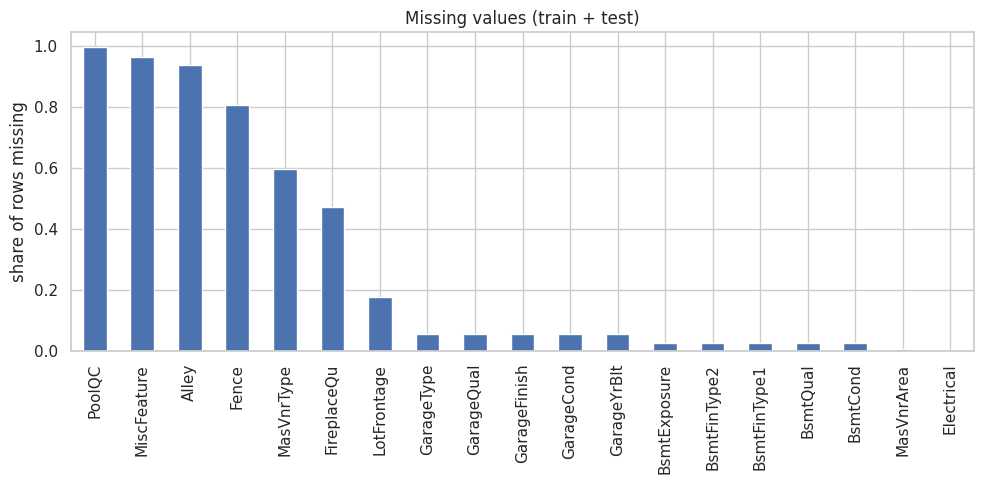

In [7]:
missing = pd.concat([train_df.drop(columns='SalePrice'), test_df]).isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]

plt.figure(figsize=(10, 5))
missing.plot(kind='bar')
plt.ylabel('share of rows missing')
plt.title('Missing values (train + test)')
plt.tight_layout()
plt.show()

## 2. Cleaning and feature engineering
Most of these values are not really missing. The data dictionary says NA in `PoolQC`, `Alley`, `Fence`, `FireplaceQu`, and the garage and basement columns means the house doesn't have that feature, so we fill them with "None" (or 0 for ratings). `LotFrontage` is genuinely missing for about 17% of rows; it gets the median inside the model pipeline.

Other steps:
- Quality ratings (Ex/Gd/TA/Fa/Po) have a natural order, so we map them to 5..1 instead of one-hot encoding them. 0 means the feature is absent.
- `MSSubClass` is stored as a number but is a category code.
- New features: `TotalSF` (basement + 1st + 2nd floor), `TotalBath`, `HouseAge` and `RemodAge` at the time of sale, `TotalPorchSF`, and `QualSF` (OverallQual × GrLivArea), since a large house is worth more when it is also high quality.

The same function is applied to train and test so the columns always match.

In [8]:
QUALITY = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1}
ORDINAL_MAPS = {col: QUALITY for col in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
                                         'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']}
ORDINAL_MAPS['BsmtExposure'] = {'Gd': 4, 'Av': 3, 'Mn': 2, 'No': 1}
ORDINAL_MAPS['BsmtFinType1'] = ORDINAL_MAPS['BsmtFinType2'] = {'GLQ': 6, 'ALQ': 5, 'BLQ': 4, 'Rec': 3, 'LwQ': 2, 'Unf': 1}
ORDINAL_MAPS['GarageFinish'] = {'Fin': 3, 'RFn': 2, 'Unf': 1}

# In these columns NaN means the house doesn't have the feature (no alley, no fence, ...)
NONE_COLS = ['Alley', 'MasVnrType', 'Fence', 'MiscFeature', 'GarageType']


def prepare_features(df):
    df = df.copy()

    # quality ratings become numbers; a missing rating means no basement/garage/pool -> 0
    for col, mapping in ORDINAL_MAPS.items():
        df[col] = df[col].map(mapping).fillna(0)
    df[NONE_COLS] = df[NONE_COLS].fillna('None')
    df['MasVnrArea'] = df['MasVnrArea'].fillna(0)
    df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])

    # MSSubClass is a dwelling-type code, not a quantity
    df['MSSubClass'] = df['MSSubClass'].astype(str)

    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    df['TotalBath'] = df['FullBath'] + 0.5 * df['HalfBath'] + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath']
    df['HouseAge'] = df['YrSold'] - df['YearBuilt']
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
    df['TotalPorchSF'] = df[['WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch']].sum(axis=1)
    df['QualSF'] = df['OverallQual'] * df['GrLivArea']

    return df.drop(columns='Id')

In [9]:
X = prepare_features(train_df.drop(columns='SalePrice'))
y = train_df['SalePrice']
X_test = prepare_features(test_df)

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
# right-skewed size/area columns get a log transform in the linear models
skew_cols = [c for c in num_cols if X[c].min() >= 0 and abs(X[c].skew()) > 0.75]

print(f'{len(num_cols)} numeric, {len(cat_cols)} categorical, {len(skew_cols)} skewed numeric columns')
# whatever is still missing gets the median / 'None' imputer inside the pipeline
print('still missing in X:', X.isna().sum()[lambda s: s > 0].to_dict())
print('still missing in X_test:', X_test.isna().sum()[lambda s: s > 0].to_dict())

55 numeric, 30 categorical, 31 skewed numeric columns
still missing in X: {'LotFrontage': 210}
still missing in X_test: {'LotFrontage': 49, 'Electrical': 1}


## 3. Modeling setup
Preprocessing lives inside a scikit-learn pipeline, so imputation and scaling are learned only from the training folds during CV and nothing leaks from the validation fold. Categorical columns are one-hot encoded with `handle_unknown='ignore'` because the test set has a few categories that never appear in training (for example `RoofMatl` "Roll" and `Heating` "Floor"). For the linear models we can also log-transform the skewed area columns. `log_target` wraps a model so it trains on log(SalePrice) but predicts in dollars.

In [10]:
def make_preprocessor(log_skewed=False):
    plain_num = [c for c in num_cols if not (log_skewed and c in skew_cols)]
    transformers = [
        ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), plain_num),
        ('cat', make_pipeline(SimpleImputer(strategy='constant', fill_value='None'),
                              OneHotEncoder(handle_unknown='ignore', sparse_output=False)), cat_cols),
    ]
    if log_skewed:
        transformers.append(('skewed', make_pipeline(SimpleImputer(strategy='median'),
                                                     FunctionTransformer(np.log1p, feature_names_out='one-to-one'),
                                                     StandardScaler()), skew_cols))
    return ColumnTransformer(transformers)


def log_target(model):
    # fit on log(SalePrice), predictions come back in dollars
    return TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)


cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def cv_rmse(model):
    scores = -cross_val_score(model, X, y, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    return scores.mean(), scores.std()

In [11]:
alphas = np.logspace(-1, 3, 40)

candidates = {
    'Mean baseline': DummyRegressor(),
    'Linear regression': make_pipeline(make_preprocessor(), LinearRegression()),
    'Ridge': make_pipeline(make_preprocessor(), RidgeCV(alphas=alphas)),
    'Ridge (log target)': log_target(make_pipeline(make_preprocessor(), RidgeCV(alphas=alphas))),
    'Ridge (log target + log skewed)': log_target(make_pipeline(make_preprocessor(log_skewed=True), RidgeCV(alphas=alphas))),
    'Lasso (log target + log skewed)': log_target(make_pipeline(make_preprocessor(log_skewed=True),
                                                                LassoCV(alphas=np.logspace(-4.5, -1.5, 30), max_iter=50000))),
    'Random forest': make_pipeline(make_preprocessor(), RandomForestRegressor(n_estimators=500, random_state=RANDOM_STATE)),
    'Gradient boosting (log target)': log_target(make_pipeline(make_preprocessor(), GradientBoostingRegressor(
        n_estimators=1500, learning_rate=0.02, max_depth=3, subsample=0.8, max_features='sqrt', random_state=RANDOM_STATE))),
}

rows = []
for name, model in candidates.items():
    mean_rmse, std_rmse = cv_rmse(model)
    rows.append({'model': name, 'cv_rmse': mean_rmse, 'std': std_rmse})

results = pd.DataFrame(rows).sort_values('cv_rmse').reset_index(drop=True)
results.style.format({'cv_rmse': '${:,.0f}', 'std': '${:,.0f}'})

,model,cv_rmse,std
0,Ridge (log target + log skewed),"$26,579","$6,748"
1,Lasso (log target + log skewed),"$26,963","$6,879"
2,Gradient boosting (log target),"$27,127","$8,300"
3,Ridge (log target),"$28,754","$13,370"
4,Random forest,"$30,094","$6,748"
5,Ridge,"$30,853","$7,361"
6,Linear regression,"$35,606","$7,856"
7,Mean baseline,"$80,817","$7,003"


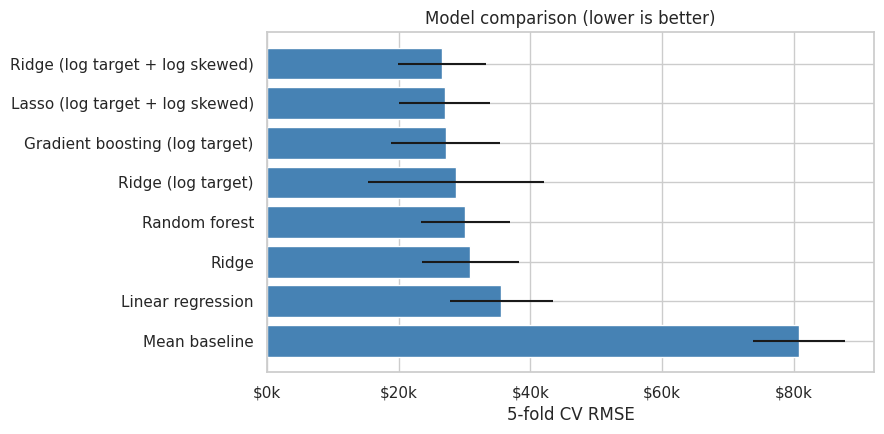

In [12]:
plt.figure(figsize=(9, 4.5))
plot_df = results.sort_values('cv_rmse', ascending=False)
plt.barh(plot_df['model'], plot_df['cv_rmse'], xerr=plot_df['std'], color='steelblue')
plt.gca().xaxis.set_major_formatter(usd_k)
plt.xlabel('5-fold CV RMSE')
plt.title('Model comparison (lower is better)')
plt.tight_layout()
plt.show()

What the comparison shows:
- Every model beats the mean baseline by a wide margin (\$80.8k down to \$36k or less).
- Plain linear regression overfits the ~250 columns created by one-hot encoding; Ridge's regularization helps (\$30.9k).
- Training Ridge on log(SalePrice) helps, and log-transforming the skewed area columns as well helps more: \$26.6k, the best single model.
- Gradient boosting is close behind (\$27.1k); random forest is weaker (\$30.1k).

Ridge and gradient boosting make different kinds of mistakes (one is linear, the other is tree-based), so combining their predictions should reduce the error. First we tune the boosting model a little.

In [13]:
gbr_search = GridSearchCV(
    log_target(make_pipeline(make_preprocessor(), GradientBoostingRegressor(
        n_estimators=1500, subsample=0.8, max_features='sqrt', random_state=RANDOM_STATE))),
    param_grid={
        'regressor__gradientboostingregressor__max_depth': [2, 3, 4],
        'regressor__gradientboostingregressor__learning_rate': [0.01, 0.02],
    },
    cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1,
)
gbr_search.fit(X, y)

gbr_params = {k.split('__')[-1]: v for k, v in gbr_search.best_params_.items()}
print('best params:', gbr_params)
print(f'CV RMSE: ${-gbr_search.best_score_:,.0f}')

best params: {'learning_rate': 0.02, 'max_depth': 4}
CV RMSE: $26,628


In [14]:
ridge_model = log_target(make_pipeline(make_preprocessor(log_skewed=True), RidgeCV(alphas=alphas)))
gbr_model = log_target(make_pipeline(make_preprocessor(), GradientBoostingRegressor(
    n_estimators=1500, subsample=0.8, max_features='sqrt', random_state=RANDOM_STATE, **gbr_params)))
# same trees but with Huber loss, which is less sensitive to a few very wrong prices
gbr_huber_model = log_target(make_pipeline(make_preprocessor(), GradientBoostingRegressor(
    loss='huber', n_estimators=2000, subsample=0.8, max_features='sqrt', random_state=RANDOM_STATE, **gbr_params)))

blend_parts = {'ridge': ridge_model, 'gbr': gbr_model, 'gbr_huber': gbr_huber_model}
oof_parts = pd.DataFrame({name: cross_val_predict(m, X, y, cv=cv, n_jobs=-1) for name, m in blend_parts.items()})

# every weight combination in steps of 0.1 that sums to 1
weight_grid = [(a / 10, b / 10, (10 - a - b) / 10) for a in range(11) for b in range(11 - a)]
weight_rmse = {w: np.sqrt(np.mean((y - oof_parts.values @ np.array(w)) ** 2)) for w in weight_grid}
best_weights = min(weight_rmse, key=weight_rmse.get)

print('out-of-fold RMSE of each model:', {k: f'${np.sqrt(np.mean((y - v) ** 2)):,.0f}' for k, v in oof_parts.items()})
print(f'equal Ridge + GBR: ${weight_rmse[(0.5, 0.5, 0.0)]:,.0f} | best weights {best_weights}: ${weight_rmse[best_weights]:,.0f}')

out-of-fold RMSE of each model: {'ridge': '$27,422', 'gbr': '$27,740', 'gbr_huber': '$27,748'}
equal Ridge + GBR: $26,864 | best weights (0.5, 0.2, 0.3): $26,805


In [15]:
final_model = VotingRegressor(list(blend_parts.items()), weights=list(best_weights))

blend_rmse, blend_std = cv_rmse(final_model)
print(f'Weighted blend CV RMSE: ${blend_rmse:,.0f} (+/- ${blend_std:,.0f})')

Weighted blend CV RMSE: $25,802 (+/- $7,264)


Deeper trees (`max_depth=4`) with learning rate 0.02 worked best for gradient boosting. We also added a second boosting model with Huber loss, which is less affected by a few houses with very unusual prices. Instead of averaging equally, we tried every combination of weights in steps of 0.1 and picked the one with the lowest out-of-fold RMSE: Ridge 0.5, GBR 0.2, Huber GBR 0.3. The gain over an equal Ridge + GBR average is small (out-of-fold RMSE \$26.9k vs \$26.8k), and the 5-fold CV RMSE of the weighted blend is \$25.8k.

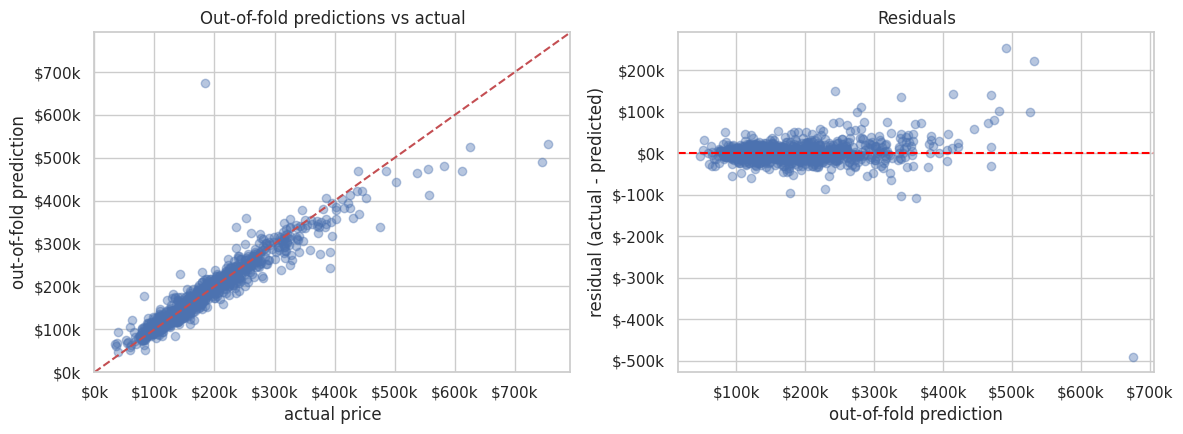

        Id  actual  predicted  abs_error
523    524  184750   675417.0   490667.0
1182  1183  745000   490885.0   254115.0
691    692  755000   531855.0   223145.0
688    689  392000   242672.0   149328.0
1046  1047  556581   414457.0   142124.0
OOF RMSE: $26,805
OOF RMSE without Id 524: $22,766


In [16]:
oof_pred = cross_val_predict(final_model, X, y, cv=cv, n_jobs=-1)
oof_err = pd.DataFrame({'Id': train_df['Id'], 'actual': y, 'predicted': oof_pred,
                        'abs_error': np.abs(y - oof_pred)})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(oof_err['actual'], oof_err['predicted'], alpha=0.4)
lims = [0, oof_err[['actual', 'predicted']].max().max() * 1.05]
axes[0].plot(lims, lims, 'r--')
axes[0].set(xlim=lims, ylim=lims, xlabel='actual price', ylabel='out-of-fold prediction',
            title='Out-of-fold predictions vs actual')
axes[1].scatter(oof_err['predicted'], oof_err['actual'] - oof_err['predicted'], alpha=0.4)
axes[1].axhline(0, color='red', linestyle='--')
for ax in axes:
    ax.xaxis.set_major_formatter(usd_k)
    ax.yaxis.set_major_formatter(usd_k)
axes[1].set(xlabel='out-of-fold prediction', ylabel='residual (actual - predicted)', title='Residuals')
plt.tight_layout()
plt.show()

print(oof_err.sort_values('abs_error', ascending=False).head(5).round(0))
print(f"OOF RMSE: ${np.sqrt(np.mean((y - oof_pred) ** 2)):,.0f}")
print(f"OOF RMSE without Id 524: ${np.sqrt(np.mean((y - oof_pred)[train_df['Id'] != 524] ** 2)):,.0f}")

Most predictions sit close to the diagonal. Errors get larger above roughly \$400k, where the model tends to underpredict because there are few training houses at that price. The single largest error is Id 524 (predicted about \$675k, sold for \$185k). Without that one house the out-of-fold RMSE drops from \$26.8k to \$22.8k, so one unusual sale is a big part of our error.

### Houses outside the training range
Our first Kaggle submission scored \$45.7k, much worse than our CV estimate of \$25.9k. One test house (Id 1299) is bigger than anything in the training data: 5,642 sq ft above ground and 11,752 total sq ft, compared with training maximums of 4,676 and 7,814. Ridge extrapolates its linear trend and predicts over \$1M for that house, more than any house in the training set sold for. Gradient boosting can't extrapolate beyond the training data, so it gives about \$290k (both predictions are printed in the submission cell below).

Rule: if a house's living area or square footage is larger than every training house, we use only the gradient boosting prediction. In CV the rule triggers for 3 validation houses and the score barely changes (\$25.8k → \$25.9k), so it doesn't hurt normal houses.

In [17]:
SIZE_COLS = ['GrLivArea', 'TotalSF', 'TotalBsmtSF', '1stFlrSF']


def predict_in_range(model, X_train, X_new):
    """Blend prediction, but houses larger than any training house get the gradient boosting prediction only."""
    pred = model.predict(X_new)
    outside = (X_new[SIZE_COLS] > X_train[SIZE_COLS].max()).any(axis=1)
    if outside.any():
        pred[outside.values] = model.named_estimators_['gbr'].predict(X_new[outside])
    return pred, outside


# same 5 folds as before, so the score is comparable with the plain blend
fold_scores, n_outside = [], 0
for train_idx, val_idx in cv.split(X):
    fold_model = clone(final_model).fit(X.iloc[train_idx], y.iloc[train_idx])
    pred, outside = predict_in_range(fold_model, X.iloc[train_idx], X.iloc[val_idx])
    fold_scores.append(np.sqrt(np.mean((y.iloc[val_idx] - pred) ** 2)))
    n_outside += outside.sum()

print(f'CV RMSE with out-of-range rule: ${np.mean(fold_scores):,.0f} (plain blend: ${blend_rmse:,.0f})')
print(f'validation rows that used gradient boosting only: {n_outside}')

CV RMSE with out-of-range rule: $25,888 (plain blend: $25,802)
validation rows that used gradient boosting only: 3


Ridge alpha: 11.253355826007645


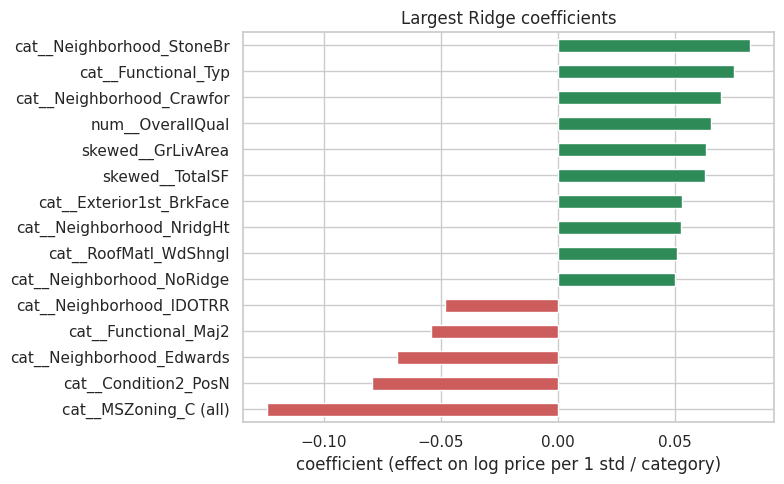

In [18]:
final_model.fit(X, y)

ridge_fitted = final_model.named_estimators_['ridge'].regressor_
coefs = pd.Series(ridge_fitted[-1].coef_, index=ridge_fitted[0].get_feature_names_out())
top_coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)
print('Ridge alpha:', ridge_fitted[-1].alpha_)

plt.figure(figsize=(8, 5))
top_coefs.sort_values().plot(kind='barh', color=np.where(top_coefs.sort_values() > 0, 'seagreen', 'indianred'))
plt.xlabel('coefficient (effect on log price per 1 std / category)')
plt.title('Largest Ridge coefficients')
plt.tight_layout()
plt.show()

Location matters a lot: StoneBr, Crawfor, NridgHt and NoRidge push prices up, while IDOTRR and Edwards push them down. Overall quality, living area and total square footage are the biggest numeric effects. Commercial zoning (`C (all)`) and major functional deductions lower the price.

In [19]:
test_pred, outside_test = predict_in_range(final_model, X, X_test)
print('test houses larger than any training house:', test_df.loc[outside_test.values, 'Id'].tolist())
parts = final_model.named_estimators_
print('  Ridge prediction:', parts['ridge'].predict(X_test[outside_test]).round(0))
print('  GBR prediction:  ', parts['gbr'].predict(X_test[outside_test]).round(0))

# sample_soln.csv numbers rows 0..259 (position in test.csv), not the 1201-1460 Id column
submission = pd.DataFrame({'Id': np.arange(len(test_df)), 'SalePrice': test_pred})
submission.to_csv('submission.csv', index=False)

assert submission['Id'].tolist() == list(range(260)) and submission['SalePrice'].notna().all()
assert (submission['SalePrice'] > 0).all()
print(submission.shape)
print(submission['SalePrice'].describe().round(0))
submission.head()

test houses larger than any training house: [1299]
  Ridge prediction: [1022884.]
  GBR prediction:   [288994.]
(260, 2)
count       260.0
mean     179920.0
std       69150.0
min       63833.0
25%      132773.0
50%      163956.0
75%      213920.0
max      441367.0
Name: SalePrice, dtype: float64


,Id,SalePrice
0,0,98552.032111
1,1,199986.178750
2,2,134197.067758
3,3,201257.916031
4,4,148666.704963


## Conclusion
Final model: a weighted blend of Ridge regression (log target, log-transformed skewed features), gradient boosting and Huber-loss gradient boosting (weights 0.5 / 0.2 / 0.3), with gradient boosting alone for houses larger than any training house.

- 5-fold CV RMSE: about \$25.9k (mean baseline: \$80.8k)
- Kaggle public leaderboard: \$45,729 for the first blend, \$17,990 after adding the out-of-range rule, \$17,884 for the weighted blend

The test set includes a very large partial-sale house, similar to the Id 524 case in training, so the leaderboard error depends heavily on that one prediction. Next steps would be modeling partial sales of very large houses more carefully and adding neighborhood-level features.